# 05 — Economic risk and best sowing date

For each municipality × sowing date, the second-season maize margin is simulated over the 26 years with
available cost data (harvests 2000–2025), **pairing the weather, the harvest-month price and the cost of
the same year**, and drawing yield from the quantiles of the hybrid model (notebook 03).

- **Margin** = price × yield × (1 − Funrural) − (operating cost per ha + cost per kg × yield) + insurance indemnity.
- **Official ZARC**: risk table of the 2026/2027 season (Portaria SPA/MAPA nº 329/2026; MAPA open
  data), second-season maize, rainfed, **Group I** (earliest cycle; Group II as sensitivity). The soil
  available-water class (AD1–AD6, IN SPA/MAPA nº 1/2022) of each municipality comes from the municipal
  DTA. A date is suitable when the corresponding ten-day period has an indicated risk (20, 30 or 40%).
- **Field-level risk**: the model predicts the municipal mean yield; an individual field varies more.
  The idiosyncratic variance (τ², in log) is calibrated so that the frequency of yield below 65% of the
  expected value reproduces the fraction of indemnified policies of the PSR in Paraná (2016–2024).
- **Insurance**: only ZARC-suitable combinations have access to subsidized crop insurance/PROAGRO.
  Yield insurance with 65% coverage of the expected yield; in unsuitable combinations there is no
  indemnity and the premium is removed from the cost.
- **Assumptions and sources**:
  - *Funrural* 1.5% of gross revenue = 1.2% (social security) + 0.1% (RAT) + 0.2% (SENAR), individual
    farmer — Law 8,212/1991, art. 25, as amended by Law 13,606/2018.
  - *Insurance coverage* 65% of expected yield: level of 75% of the 132,673 second-season maize
    policies in Paraná subsidized by the PSR in 2016–2025 (19% at 70%; SISSER/MAPA open data,
    `dados/psr_milho2safra_pr_resumo_anual.csv`). Sensitivity with 70%.
  - *Insurance access only within ZARC*: the premium subsidy (PSR) and PROAGRO require planting
    according to the zoning (MCR, ch. 16; PSR rules).
  - *Physiological maturity → sale* in 20 days: at black layer the grain has ~30–35% moisture and is
    harvested at 18–22% (Embrapa Maize and Sorghum); field drying is 0.4–0.8 percentage points per day
    (Iowa State University; Purdue), i.e. 15–25 days. Sensitivity with 10 and 30 days.
- **Decision**: certainty equivalent (CE) with exponential (CARA) utility over a range of risk aversion
  — *stochastic efficiency with respect to a function*, SERF (Hardaker et al., 2004) —, probability of
  loss and CVaR 10% (mean of the worst 10% outcomes).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import logsumexp
from scipy.stats import norm

import mapas
from sensibilidade import SAIDA, SENS, entrada

plt.rcParams.update({"font.size": 16})

RAIZ = Path.cwd().parent
DADOS, RESULTADOS, FIGURAS = RAIZ / "dados", RAIZ / "resultados", RAIZ / "figuras"
if SENS:
    FIGURAS = SAIDA
rng = np.random.default_rng(42)

ORDEM_DATAS = [f"{d:02d}/{m:02d}" for m in (1, 2, 3) for d in (5, 15, 25)]
ANOS = range(2000, 2026)
N_SORTEIOS = 200
DIAS_ATE_VENDA = 20          # physiological maturity → harvest and sale
FUNRURAL = 0.015             # levy on gross revenue (individual farmer, Law 13,606/2018)
COBERTURA = 0.65             # coverage level of yield insurance
RISCO_RELATIVO = [0, 0.5, 1, 2, 3, 4]  # Anderson & Dillon (1992): 0.5 hardly ... 4 extremely averse
RR_REFERENCIA = 2
GRUPO_ZARC = 20              # Group I (ZARC table: 20 = Group I, 21 = Group II)
JANELA = ["15/01", "25/01", "05/02", "15/02", "25/02", "05/03", "15/03"]
DECENDIO = {f"{d:02d}/{m:02d}": (m - 1) * 3 + {5: 1, 15: 2, 25: 3}[d] for m in (1, 2, 3) for d in (5, 15, 25)}

prod = pd.read_parquet(entrada("produtividade_prevista_pr.parquet"))
# Decision only where IBGE has second-season records (elsewhere the model extrapolates: cold plateau, no second season)
print("Municipalities without second-season records (outside the analysis):", prod.loc[prod["sem_historico_ibge"], "cod_ibge"].nunique())
prod = prod[~prod["sem_historico_ibge"]]
sim = pd.read_parquet(entrada("simulacao_mza_pr.parquet"),
                      columns=["cod_ibge", "ano", "semeadura", "zarc_ISNA_I", "zarc_ISNA_III",
                               "zarc_tmed_floracao", "zarc_geada_I_III"])
custos = pd.read_csv(RESULTADOS / "custos_milho_safrinha_real.csv").set_index("ano")
precos = pd.read_csv(RESULTADOS / "precos_milho_pr_mensal_real.csv").set_index(["ano", "mes"])["preco_real_kg"]
mun = pd.read_csv(DADOS / "municipios_pr.csv").set_index("cod_ibge")

Municipalities without second-season records (outside the analysis): 26


## 1. Official ZARC (2026/2027 risk table)

In [2]:
# Available-water class (mm/cm) from the municipal DTA — limits of IN SPA/MAPA nº 1/2022
LIMITES_AD = [0, 0.465, 0.615, 0.805, 1.065, 1.405, 99]
mun["cod_solo_ad"] = pd.cut(mun["dta_mm_m"] / 100, LIMITES_AD, labels=[11, 12, 13, 14, 15, 16]).astype(int)
print(mun["cod_solo_ad"].map({11: "AD1", 12: "AD2", 13: "AD3", 14: "AD4", 15: "AD5", 16: "AD6"}).value_counts().sort_index().to_dict())

tabua = pd.read_csv(DADOS / "zarc_milho2safra_pr_2026_2027.csv")
tabua = tabua.drop_duplicates(["geocodigo", "Cod_Ciclo", "Cod_Solo"])


def zarc_oficial(grupo):
    t = tabua[tabua["Cod_Ciclo"] == grupo].set_index(["geocodigo", "Cod_Solo"])
    linhas = []
    for cod, ad in mun["cod_solo_ad"].items():
        for data, dec in DECENDIO.items():
            risco = t.at[(cod, ad), f"dec{dec}"] if (cod, ad) in t.index else 0
            linhas.append({"cod_ibge": cod, "semeadura": data, "risco_zarc": int(risco)})
    z = pd.DataFrame(linhas)
    z["classe_zarc"] = z["risco_zarc"].map({20: "20%", 30: "30%", 40: "40%"}).fillna("Inapto")
    z["apto"] = z["risco_zarc"] > 0
    return z


zarc = zarc_oficial(GRUPO_ZARC)
pd.crosstab(zarc["semeadura"], zarc["classe_zarc"]).loc[ORDEM_DATAS, ["20%", "30%", "40%", "Inapto"]]

{'AD2': 17, 'AD3': 44, 'AD4': 54, 'AD5': 263, 'AD6': 21}


classe_zarc,20%,30%,40%,Inapto
semeadura,,,,
05/01,333,41,21,4
15/01,280,57,34,28
25/01,219,79,56,45
05/02,128,97,87,87
15/02,120,85,69,125
25/02,82,95,75,147
05/03,155,48,37,159
15/03,120,88,18,173
25/03,0,0,0,399


### 1.1 Does the replica of the ZARC water balance agree with the official ZARC?

Test of MZA itself: the replica of the ordinance's water criterion (100-day cycle; adverse if ISNA of
phase I ≤ 0.70 or of phase III ≤ 0.55; suitable if ≤ 40% of years are adverse) compared with the
official table.

In [3]:
sim["adverso"] = (sim["zarc_ISNA_I"] <= 0.70) | (sim["zarc_ISNA_III"] <= 0.55)
replica = sim.groupby(["cod_ibge", "semeadura"])["adverso"].mean().rename("freq_adverso_replica").reset_index()
cmp_z = zarc.merge(replica, on=["cod_ibge", "semeadura"])
cmp_z["apto_replica"] = cmp_z["freq_adverso_replica"] <= 0.40
concord = (cmp_z["apto"] == cmp_z["apto_replica"]).mean()
print(f"Suitable/unsuitable agreement replica × official: {concord:.1%}")
pd.crosstab(cmp_z["apto"], cmp_z["apto_replica"], rownames=["official"], colnames=["replica"])

Suitable/unsuitable agreement replica × official: 39.1%


replica,False,True
official,,
False,568,599
True,1587,837


## 2. Harvest-month price and cost structure

In [4]:
det = pd.read_excel(DADOS / "custos.xlsx", sheet_name="so_a_base", header=None)
itens = det.iloc[5:, [1, 5, 11]]
itens.columns = ["cultura", "item", "valor"]
milho2 = itens[itens["cultura"] == 7].set_index("item")["valor"].apply(pd.to_numeric, errors="coerce").fillna(0)
VARIAVEIS = ["Operação de máquinas e implementos", "Despesas de manutenção de benfeitorias", "Mão-de-obra temporária",
             "Sementes/Manivas", "Fertilizantes", "Agrotóxicos", "Despesas gerais", "Transporte externo",
             "Assistência técnica", "PROAGRO/SEGURO", "Juros"]
FRAC_PREMIO = milho2["PROAGRO/SEGURO"] / milho2[VARIAVEIS].sum()
print(f"PROAGRO/insurance premium = {FRAC_PREMIO:.1%} of variable cost (DERAL, May/2026)")

df = prod[prod["ano"].isin(ANOS)].merge(zarc[["cod_ibge", "semeadura", "classe_zarc", "apto"]],
                                         on=["cod_ibge", "semeadura"])


def preco_de_venda(dias):
    venda = pd.to_datetime(df["data_maturacao"]) + pd.Timedelta(days=dias)
    return precos.reindex(pd.MultiIndex.from_arrays([venda.dt.year, venda.dt.month])).to_numpy(), venda.dt.month


df["preco_kg"], df["mes_venda"] = preco_de_venda(DIAS_ATE_VENDA)
c = custos.reindex(df["ano"])
df["custo_ha"] = c["custo_operacional_ha_fixo"].to_numpy()
df["custo_ha_total"] = c["custo_total_ha_fixo"].to_numpy()
df["custo_kg"] = c["custo_var_real_kg"].to_numpy()
df["premio_ha"] = FRAC_PREMIO * c["custo_var_real_ha"].to_numpy()
print(df["preco_kg"].isna().sum(), "combinations without price")
df.groupby("semeadura")[["mes_venda", "preco_kg"]].mean().loc[ORDEM_DATAS].round(2).T

PROAGRO/insurance premium = 7.0% of variable cost (DERAL, May/2026)
0 combinations without price


semeadura,05/01,15/01,25/01,05/02,15/02,25/02,05/03,15/03,25/03
mes_venda,4.65,5.27,5.66,6.30,6.88,7.50,7.94,8.51,8.97
preco_kg,0.84,0.83,0.83,0.82,0.81,0.81,0.81,0.82,0.82


## 3. Field-level risk (calibration with the PSR) and Monte Carlo of the margin

log Y_field = log Y_municipality + ε, ε ~ N(0, τ²). The municipal deviation σ comes from the quantiles of
the hybrid model; τ is the only calibrated parameter: it minimizes the error between the annual
frequency of yield < 65% of expected (suitable window dates) and the fraction of indemnified policies in
the PSR, 2016–2024.

In [5]:
mu = np.log(df["rend_P50_kg_ha"].to_numpy())
sigma = (np.log(df["rend_P90_kg_ha"]) - np.log(df["rend_P10_kg_ha"])).to_numpy() / (2 * norm.ppf(0.9))
y_esperado = df.groupby(["cod_ibge", "semeadura"])["rend_P50_kg_ha"].transform("mean").to_numpy()

psr = pd.read_csv(DADOS / "psr_milho2safra_pr_resumo_anual.csv").set_index("ano")
alvo = psr.loc[2016:2024, "frac_indenizadas"]
sel = (df["semeadura"].isin(JANELA) & df["apto"] & df["ano"].between(2016, 2024)).to_numpy()
z_lim = np.log(COBERTURA * y_esperado[sel]) - mu[sel]


def freq_quebra(tau):
    p = norm.cdf(z_lim / np.sqrt(sigma[sel] ** 2 + tau ** 2))
    return pd.Series(p).groupby(df["ano"].to_numpy()[sel]).mean()


grade = np.arange(0, 0.80, 0.01)
erro = [((freq_quebra(t) - alvo) ** 2).sum() for t in grade]
TAU = float(grade[int(np.argmin(erro))])
comp_psr = pd.DataFrame({"modelo_municipio": freq_quebra(0.0), "modelo_lavoura": freq_quebra(TAU), "psr": alvo})
print(f"calibrated τ = {TAU:.2f} (mean municipal σ = {sigma.mean():.2f}); "
      f"annual r field × PSR = {comp_psr['modelo_lavoura'].corr(comp_psr['psr']):.2f}")
sigma_lav = np.sqrt(sigma ** 2 + TAU ** 2)
Y = np.exp(mu[:, None] + sigma_lav[:, None] * rng.standard_normal((len(df), N_SORTEIOS)))  # kg/ha, field
comp_psr.round(3).T

calibrated τ = 0.33 (mean municipal σ = 0.26); annual r field × PSR = 0.88


,2016,2017,2018,2019,2020,2021,2022,2023,2024
modelo_municipio,0.129,0.026,0.257,0.088,0.260,0.472,0.064,0.059,0.192
modelo_lavoura,0.215,0.098,0.303,0.168,0.326,0.473,0.138,0.142,0.262
psr,0.378,0.055,0.441,0.156,0.270,0.675,0.184,0.019,0.183


In [6]:
apto = df["apto"].to_numpy()[:, None]


def margem(custo_ha, com_seguro=True, cobertura=COBERTURA, preco=None):
    preco = df["preco_kg"].to_numpy() if preco is None else preco
    preco_seguro = pd.Series(preco).groupby([df["cod_ibge"].to_numpy(), df["semeadura"].to_numpy()]).transform("mean")
    receita = preco[:, None] * Y * (1 - FUNRURAL)
    custo = custo_ha.to_numpy()[:, None] + df["custo_kg"].to_numpy()[:, None] * Y
    if com_seguro:
        indenizacao = np.maximum(cobertura * y_esperado[:, None] - Y, 0) * preco_seguro.to_numpy()[:, None]
        return receita - custo + np.where(apto, indenizacao, 0)
    return receita - custo + df["premio_ha"].to_numpy()[:, None]  # without insurance: no premium paid


M = {"operacional": margem(df["custo_ha"]),
     "operacional_sem_seguro": margem(df["custo_ha"], com_seguro=False),
     "total": margem(df["custo_ha_total"])}
ESCALA_W = float(custos.loc[list(ANOS), "custo_total_real_ha"].mean())  # R$/ha: capital at risk
print(f"Wealth scale for absolute aversion: R$ {ESCALA_W:,.0f}/ha")

Wealth scale for absolute aversion: R$ 4,239/ha


In [7]:
grupos = df.groupby(["cod_ibge", "semeadura"]).indices


def resumo(m):
    linhas = []
    for (cod, data), idx in grupos.items():
        v = m[idx].ravel()
        pior = np.sort(v)[: max(1, int(0.10 * v.size))]
        lin = {"cod_ibge": cod, "semeadura": data, "margem_media": v.mean(), "p_prejuizo": (v < 0).mean(),
               "cvar10": pior.mean()}
        for rr in RISCO_RELATIVO:
            ra = rr / ESCALA_W
            lin[f"CE_rr{rr}"] = v.mean() if ra == 0 else -(logsumexp(-ra * v) - np.log(v.size)) / ra
        linhas.append(lin)
    return pd.DataFrame(linhas)


res = {k: resumo(m) for k, m in M.items()}
risco = (res["operacional"].merge(zarc, on=["cod_ibge", "semeadura"])
         .merge(res["operacional_sem_seguro"][["cod_ibge", "semeadura", f"CE_rr{RR_REFERENCIA}", "p_prejuizo"]]
                .rename(columns={f"CE_rr{RR_REFERENCIA}": "CE_sem_seguro", "p_prejuizo": "p_prejuizo_sem_seguro"}),
                on=["cod_ibge", "semeadura"])
         .merge(res["total"][["cod_ibge", "semeadura", "margem_media", "p_prejuizo"]]
                .rename(columns={"margem_media": "margem_media_custo_total", "p_prejuizo": "p_prejuizo_custo_total"}),
                on=["cod_ibge", "semeadura"]))
risco["valor_seguro"] = np.where(risco["apto"], risco[f"CE_rr{RR_REFERENCIA}"] - risco["CE_sem_seguro"], np.nan)
risco.to_csv(SAIDA / "risco_economico_municipio_data.csv", index=False)
risco.groupby("semeadura")[["margem_media", "p_prejuizo", "cvar10", f"CE_rr{RR_REFERENCIA}", "valor_seguro",
                            "margem_media_custo_total"]].mean().loc[ORDEM_DATAS].round(2)

,margem_media,p_prejuizo,cvar10,CE_rr2,valor_seguro,margem_media_custo_total
semeadura,,,,,,
05/01,1804.94,0.26,-1000.08,851.61,75.38,844.28
15/01,1615.89,0.28,-1122.42,725.39,59.29,655.23
25/01,1401.71,0.31,-1250.94,592.91,50.46,441.05
05/02,1223.48,0.34,-1394.83,429.93,63.76,262.82
15/02,1084.58,0.37,-1459.62,326.44,57.85,123.93
25/02,1024.73,0.38,-1534.02,277.03,50.28,64.07
05/03,1112.07,0.37,-1577.42,320.90,52.67,151.41
15/03,1248.83,0.34,-1569.81,398.72,39.46,288.17
25/03,1299.24,0.35,-1748.43,347.51,NaN,338.58


## 4. Best date per municipality

In [8]:
CE = f"CE_rr{RR_REFERENCIA}"


def melhor(df_r, so_apto):
    d = df_r[df_r["apto"]] if so_apto else df_r
    return d.loc[d.groupby("cod_ibge")[CE].idxmax()].set_index("cod_ibge")


melhor_apto = melhor(risco, True)
melhor_livre = melhor(risco, False)
neutro = risco.loc[risco.groupby("cod_ibge")["CE_rr0"].idxmax()].set_index("cod_ibge")["semeadura"]
decisao = pd.DataFrame({
    "municipio": mun["municipio"],
    "melhor_data_zarc": melhor_apto["semeadura"],
    "CE_melhor_data_zarc": melhor_apto[CE],
    "p_prejuizo_melhor_data_zarc": melhor_apto["p_prejuizo"],
    "melhor_data_sem_restricao": melhor_livre["semeadura"],
    "melhor_data_risco_neutro": neutro,
})
decisao["sem_data_apta"] = decisao["melhor_data_zarc"].isna()
decisao["muda_com_aversao"] = decisao["melhor_data_sem_restricao"] != decisao["melhor_data_risco_neutro"]
decisao.to_csv(SAIDA / "melhor_data_semeadura_pr.csv")
print("Municipalities without any ZARC-suitable date:", int(decisao["sem_data_apta"].sum()))
print("Best date changes between risk-neutral and rr=2:", int(decisao["muda_com_aversao"].sum()))
decisao["melhor_data_zarc"].value_counts().reindex(ORDEM_DATAS).fillna(0).astype(int).to_frame().T

Municipalities without any ZARC-suitable date: 27
Best date changes between risk-neutral and rr=2: 83


melhor_data_zarc,05/01,15/01,25/01,05/02,15/02,25/02,05/03,15/03,25/03
count,311,31,1,2,0,0,0,27,0


## 5. Maps

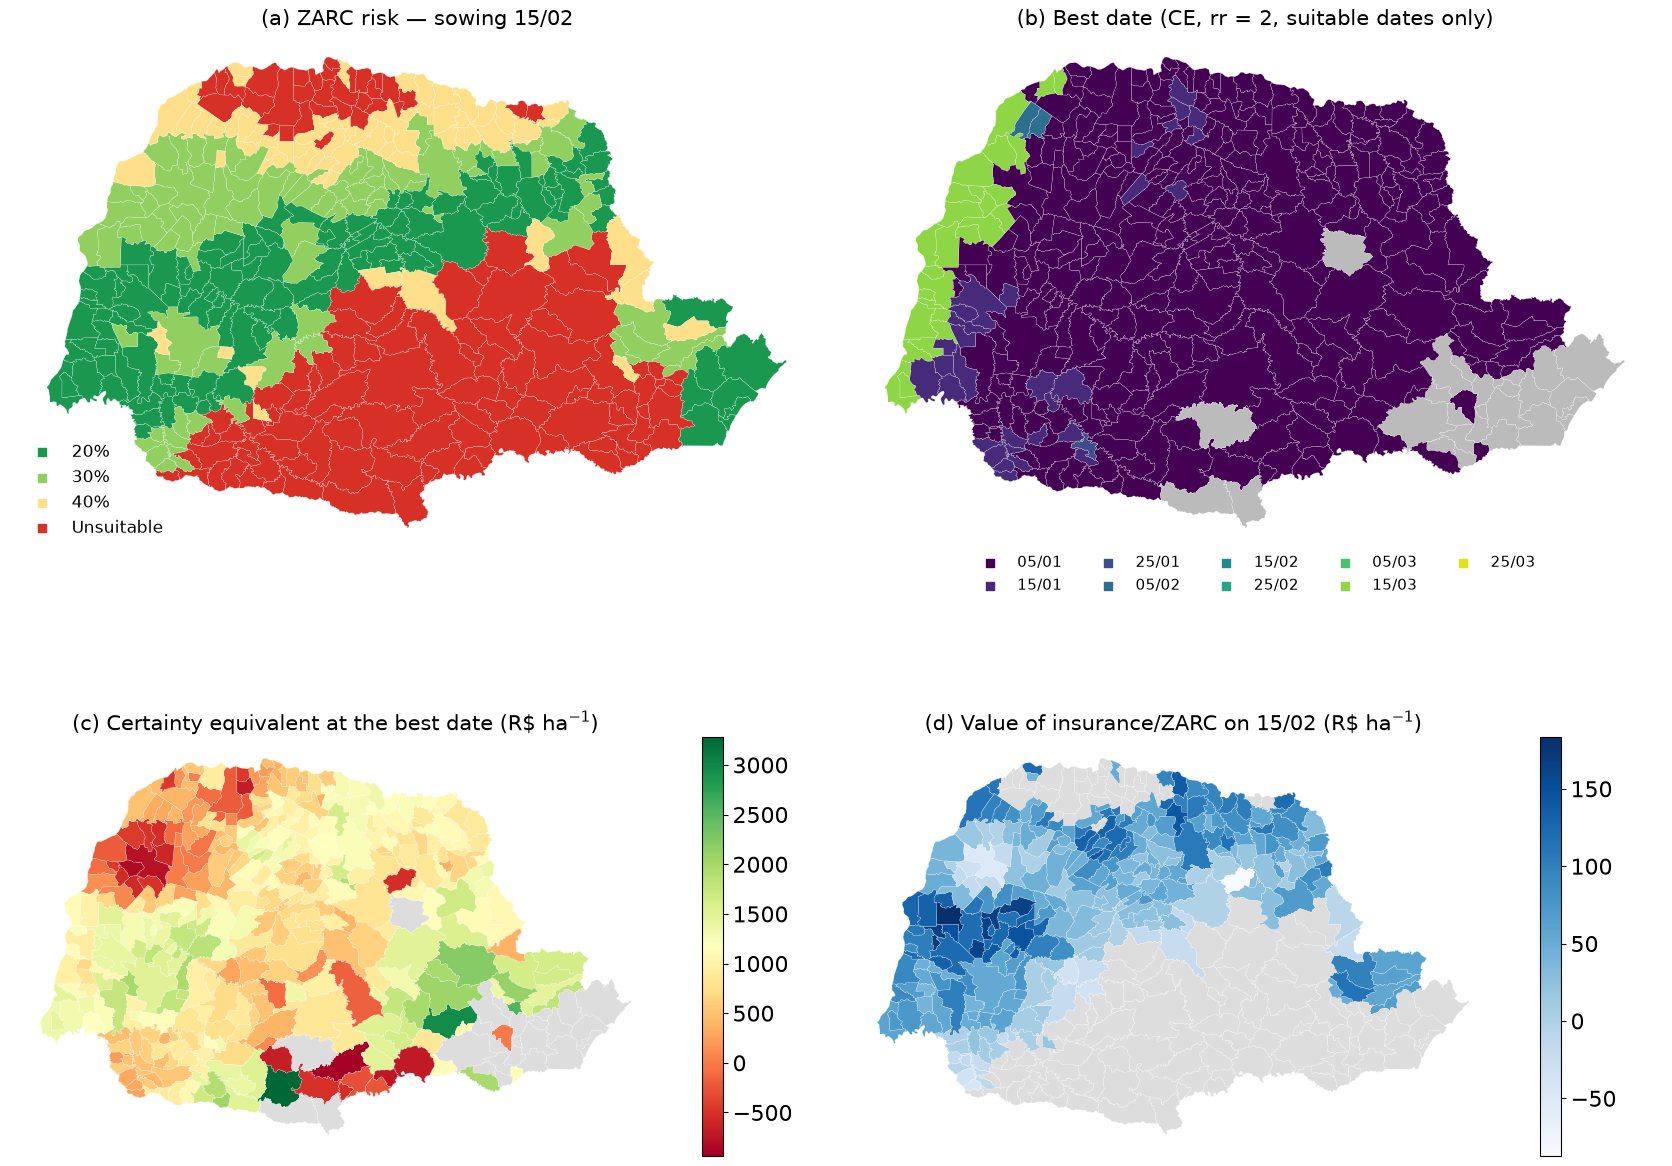

In [9]:
NOMES_ZARC = {"20%": "20%", "30%": "30%", "40%": "40%", "Inapto": "Unsuitable"}
fig, axs = plt.subplots(2, 2, figsize=(17, 14))
cores_zarc = ["#1a9850", "#91cf60", "#fee08b", "#d73027"]
z15 = zarc[zarc["semeadura"] == "15/02"].set_index("cod_ibge")["classe_zarc"].astype(str)
mapas.mapa(axs[0, 0], z15, categorias=["20%", "30%", "40%", "Inapto"], cores=cores_zarc,
           titulo="(a) ZARC risk — sowing 15/02")
cores_datas = plt.cm.viridis(np.linspace(0, 0.95, len(ORDEM_DATAS)))
mapas.mapa(axs[0, 1], decisao["melhor_data_zarc"].fillna("no suitable date"),
           categorias=ORDEM_DATAS + ["no suitable date"], cores=list(cores_datas) + ["#bbbbbb"],
           titulo=f"(b) Best date (CE, rr = {RR_REFERENCIA}, suitable dates only)")
sm = mapas.mapa(axs[1, 0], decisao["CE_melhor_data_zarc"], cmap="RdYlGn",
                titulo=r"(c) Certainty equivalent at the best date (R\$ ha$^{-1}$)")
fig.colorbar(sm, ax=axs[1, 0], shrink=0.6)
vs = risco[risco["semeadura"] == "15/02"].set_index("cod_ibge")["valor_seguro"]
sm = mapas.mapa(axs[1, 1], vs, cmap="Blues", titulo=r"(d) Value of insurance/ZARC on 15/02 (R\$ ha$^{-1}$)")
fig.colorbar(sm, ax=axs[1, 1], shrink=0.6)
for i, (cat, cor) in enumerate(zip(["20%", "30%", "40%", "Inapto"], cores_zarc)):
    axs[0, 0].scatter([], [], color=cor, label=NOMES_ZARC[cat], marker="s")
axs[0, 0].legend(frameon=False, loc="lower left", fontsize=12)
for d, cor in zip(ORDEM_DATAS, cores_datas):
    axs[0, 1].scatter([], [], color=cor, label=d, marker="s")
axs[0, 1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, 0.02), fontsize=11, ncol=5)
plt.tight_layout()
fig.savefig(FIGURAS / "fig_mapas_risco_decisao.png", dpi=300)

## 6. SERF curves (examples)

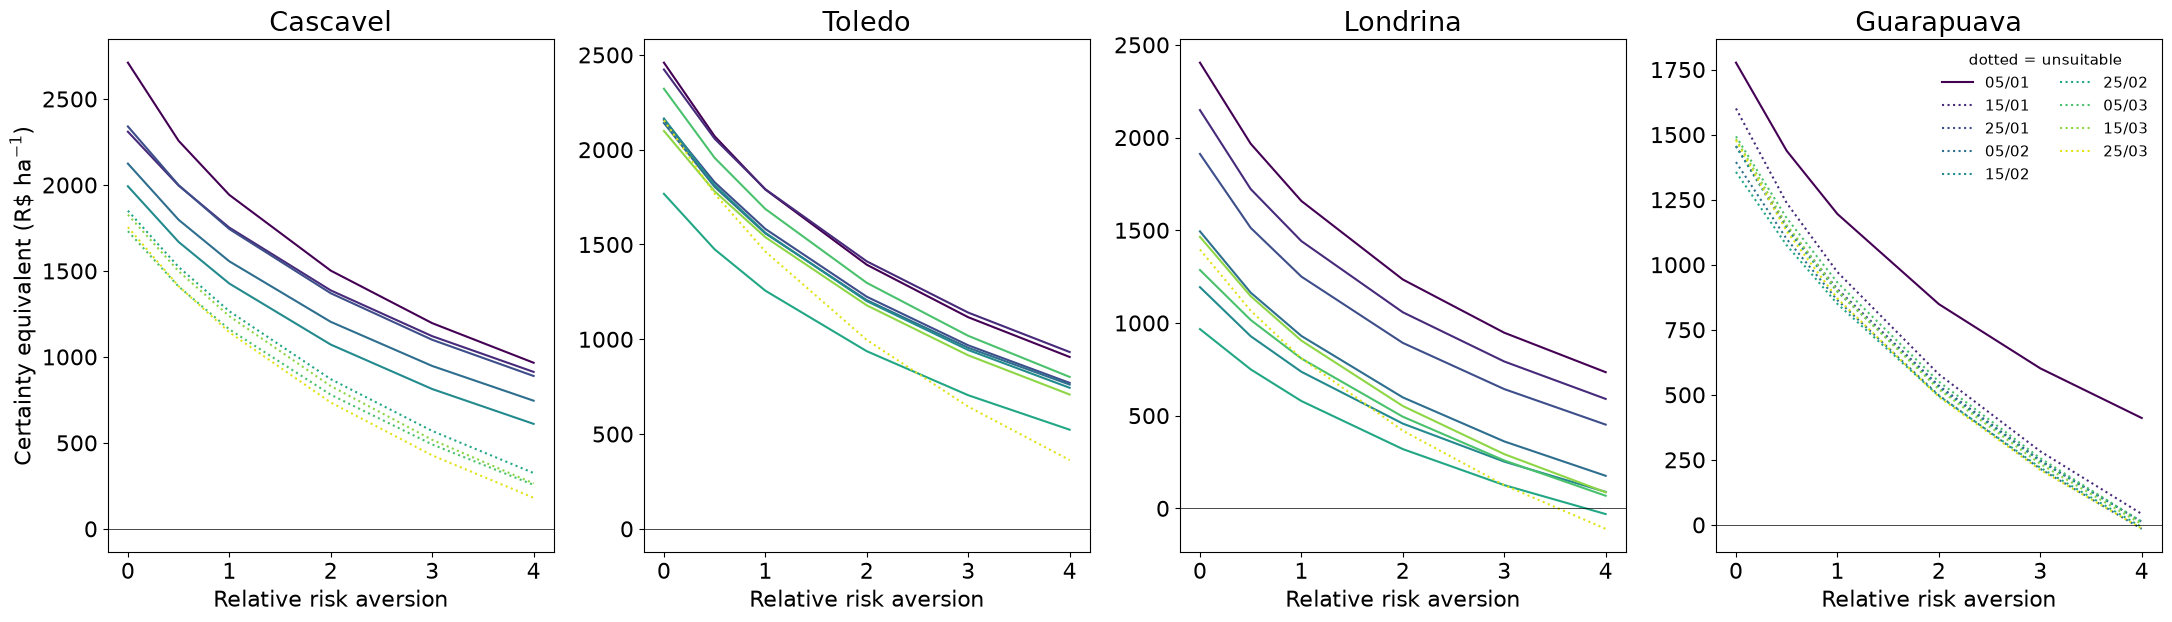

In [10]:
exemplos = ["Cascavel", "Toledo", "Londrina", "Guarapuava"]
fig, axs = plt.subplots(1, len(exemplos), figsize=(22, 6.5), sharey=False)
for ax, nome in zip(axs, exemplos):
    cod = mun.index[mun["municipio"] == nome][0]
    r = risco[risco["cod_ibge"] == cod].set_index("semeadura").loc[ORDEM_DATAS]
    for (data, linha), cor in zip(r.iterrows(), cores_datas):
        ax.plot(RISCO_RELATIVO, [linha[f"CE_rr{x}"] for x in RISCO_RELATIVO], color=cor,
                ls="-" if linha["apto"] else ":", label=data)
    ax.axhline(0, color="k", lw=0.5)
    ax.set(title=nome, xlabel="Relative risk aversion")
axs[0].set_ylabel(r"Certainty equivalent (R\$ ha$^{-1}$)")
axs[-1].legend(fontsize=11, frameon=False, ncol=2, title="dotted = unsuitable", title_fontsize=11)
plt.tight_layout()
fig.savefig(FIGURAS / "fig_serf_exemplos.png", dpi=300)

## 7. Independent validation with crop insurance (PSR)

Fraction of second-season maize policies indemnified in Paraná (SISSER/MAPA) × mean probability of yield
below 65% of expected (suitable dates of the 15/01–15/03 window), at the municipal and field level. τ only
adjusts the mean level; the correlation between years is independent information. 2025 is left out: the
indemnities are not yet processed in the open data.

Pearson r (2016–2024), municipality: 0.89; field: 0.88


,2016,2017,2018,2019,2020,2021,2022,2023,2024
modelo_municipio,0.129,0.026,0.257,0.088,0.260,0.472,0.064,0.059,0.192
modelo_lavoura,0.215,0.098,0.303,0.168,0.326,0.473,0.138,0.142,0.262
psr,0.378,0.055,0.441,0.156,0.270,0.675,0.184,0.019,0.183


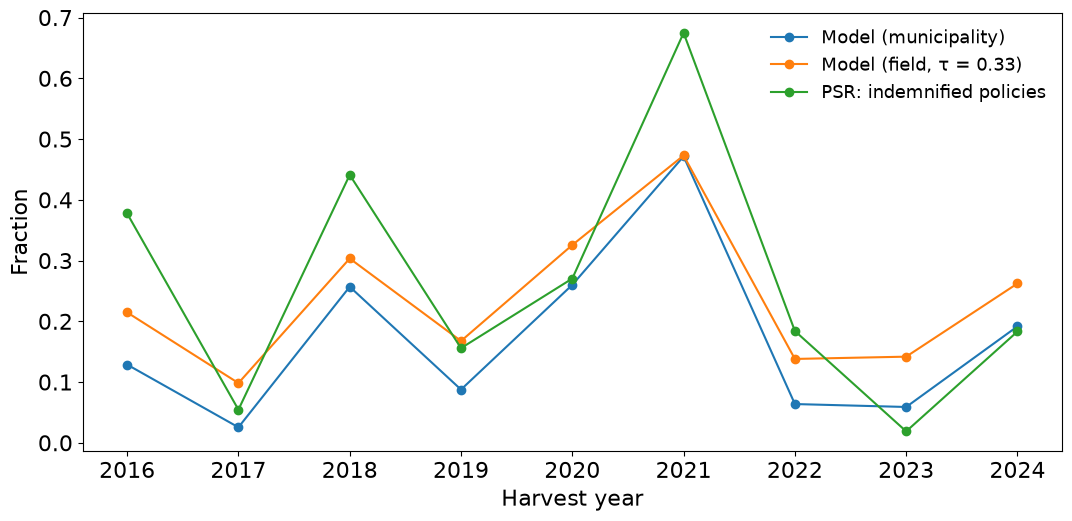

In [11]:
psr = pd.read_csv(DADOS / "psr_milho2safra_pr_resumo_anual.csv").set_index("ano")
comp = comp_psr
print(f"Pearson r (2016–2024), municipality: {comp['modelo_municipio'].corr(comp['psr']):.2f}; "
      f"field: {comp['modelo_lavoura'].corr(comp['psr']):.2f}")
fig, ax = plt.subplots(figsize=(11, 5.5))
comp.plot(ax=ax, marker="o")
ax.set(xlabel="Harvest year", ylabel="Fraction")
ax.legend(["Model (municipality)", f"Model (field, τ = {TAU:.2f})", "PSR: indemnified policies"], frameon=False, fontsize=13)
plt.tight_layout()
fig.savefig(FIGURAS / "fig_validacao_psr.png", dpi=300)
comp.round(3).T

## 8. Sensitivity: total cost, 70% coverage, ZARC Group II and 10/30 days to sale

In [12]:
def melhor_data(m, z):
    r = resumo(m).merge(z[["cod_ibge", "semeadura", "apto"]], on=["cod_ibge", "semeadura"])
    return r, melhor(r, True)["semeadura"]


zarc_g2 = zarc_oficial(21)
cenarios = {"total cost": (M["total"], zarc), "70% coverage": (margem(df["custo_ha"], cobertura=0.70), zarc)}
apto_base = apto.copy()
apto = df[["cod_ibge", "semeadura"]].merge(zarc_g2, on=["cod_ibge", "semeadura"], how="left")["apto"].fillna(False).to_numpy()[:, None]
cenarios["ZARC Group II"] = (margem(df["custo_ha"]), zarc_g2)
apto = apto_base
for dias in (10, 30):
    cenarios[f"{dias} days to sale"] = (margem(df["custo_ha"], preco=preco_de_venda(dias)[0]), zarc)
sens = []
for nome, (m, z) in cenarios.items():
    r, b = melhor_data(m, z)
    sens.append({"cenario": nome, "margem_media": r["margem_media"].mean(), "p_prejuizo": r["p_prejuizo"].mean(),
                 "mesma_melhor_data_%": 100 * b.eq(melhor_apto["semeadura"].reindex(b.index)).mean(),
                 "municipios_com_data_apta": b.size})
sens = pd.DataFrame(sens)
sens.to_csv(SAIDA / "sensibilidade_decisao.csv", index=False)
sens.round(2)

,cenario,margem_media,p_prejuizo,mesma_melhor_data_%,municipios_com_data_apta
0,total cost,352.17,0.53,97.85,372
1,70% coverage,1345.27,0.32,99.46,372
2,ZARC Group II,1307.97,0.34,95.21,355
3,10 days to sale,1324.85,0.33,90.32,372
4,30 days to sale,1307.18,0.34,90.32,372


## 9. Do the models get the risk right? Out-of-sample probability of loss

With the leave-one-year-out predictions (notebook 03), the predicted probability of loss per
municipality-year is compared with the **observed** loss (IBGE yield, typical harvest-month price of the
window, operating cost of the year). Brier score (lower = better) and reliability curve.

In [13]:
oof = pd.read_parquet(entrada("previsoes_fora_amostra.parquet"))
oof = oof[oof["ano"].isin(ANOS)].copy()
janela = sim.merge(prod[["cod_ibge", "ano", "semeadura", "data_maturacao"]], on=["cod_ibge", "ano", "semeadura"])
janela = janela[janela["semeadura"].isin(["15/01", "25/01", "05/02", "15/02", "25/02", "05/03", "15/03"])]
mat = janela.groupby(["cod_ibge", "ano"])["data_maturacao"].apply(lambda s: pd.to_datetime(s).mean())
oof = oof.merge(mat.rename("mat").reset_index(), on=["cod_ibge", "ano"])
v = oof["mat"] + pd.Timedelta(days=DIAS_ATE_VENDA)
oof["preco_kg"] = precos.reindex(pd.MultiIndex.from_arrays([v.dt.year, v.dt.month])).to_numpy()
co = custos.reindex(oof["ano"])
cf, ck = co["custo_operacional_ha_fixo"].to_numpy(), co["custo_var_real_kg"].to_numpy()
p_eq = oof["preco_kg"] * (1 - FUNRURAL) - ck                    # margin = p_eq·Y − cf
y_equilibrio = cf / p_eq                                          # break-even yield
oof["prejuizo_obs"] = oof["rendimento_kg_ha"] < y_equilibrio

MODELOS = ["A_media_historica", "B_MZA_calibrado", "C_ML_puro", "D_hibrido", "E_hibrido_monotonico",
           "F_hibrido_apsim", "H_hibrido_aquacrop", "I_hibrido_dssat", "J_hibrido_todos",
           "K_hibrido_svr", "L_ensemble_E_SVR"]
brier, conf = {}, {}
for m in MODELOS:
    res_m = oof["log_y"] - oof[m]
    p = np.empty(len(oof))
    for ano in oof["ano"].unique():
        r = res_m[oof["ano"] != ano].to_numpy()
        sel = (oof["ano"] == ano).to_numpy()
        # P(Y < y_eq) = fraction of residuals of the other years below log(y_eq) − prediction
        lim = np.log(y_equilibrio[sel].to_numpy()) - oof.loc[sel, m].to_numpy()
        p[sel] = (r[None, :] < lim[:, None]).mean(axis=1)
    oof[f"p_{m}"] = p
    brier[m] = np.mean((p - oof["prejuizo_obs"]) ** 2)
    conf[m] = oof.groupby(pd.cut(p, np.linspace(0, 1, 11)), observed=True)["prejuizo_obs"].agg(["mean", "size"])
brier = pd.Series(brier, name="Brier")
clim = oof["prejuizo_obs"].mean()
print(f"Observed loss frequency: {clim:.1%}; reference Brier (constant frequency): {clim * (1 - clim):.4f}")
brier.round(4).to_frame().T

Observed loss frequency: 55.0%; reference Brier (constant frequency): 0.2475


,A_media_historica,B_MZA_calibrado,C_ML_puro,D_hibrido,E_hibrido_monotonico,F_hibrido_apsim,H_hibrido_aquacrop,I_hibrido_dssat,J_hibrido_todos,K_hibrido_svr,L_ensemble_E_SVR
Brier,0.1728,0.1696,0.1715,0.1654,0.1706,0.1741,0.1798,0.1728,0.1734,0.1641,0.1654


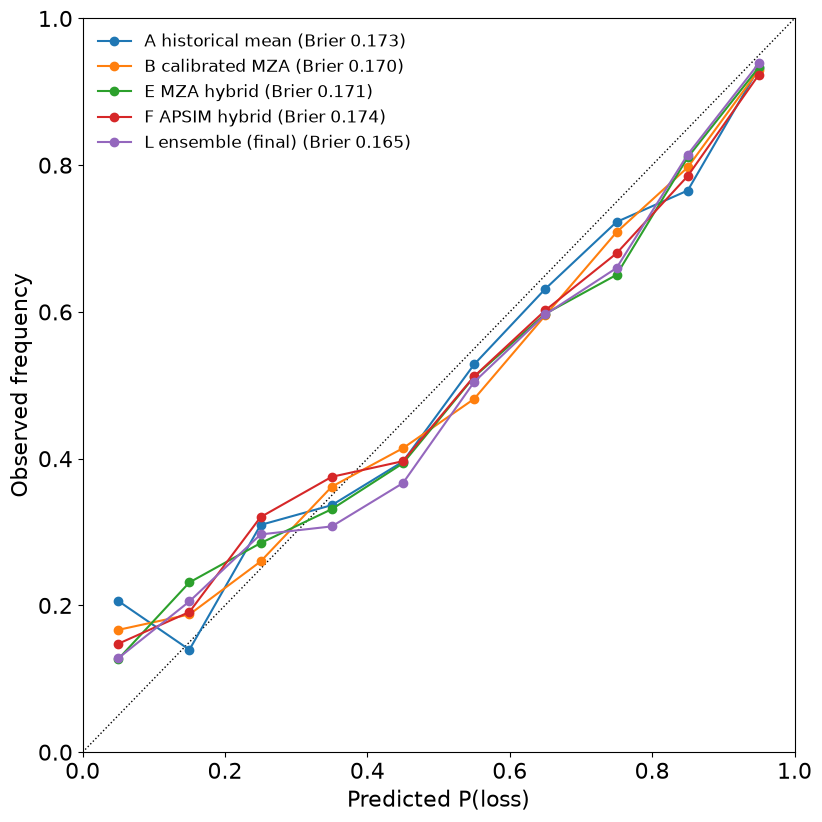

In [14]:
ROTULO = {"A_media_historica": "A historical mean", "B_MZA_calibrado": "B calibrated MZA", "E_hibrido_monotonico": "E MZA hybrid",
          "F_hibrido_apsim": "F APSIM hybrid", "L_ensemble_E_SVR": "L ensemble (final)"}
fig, ax = plt.subplots(figsize=(8.5, 8.5))
ax.plot([0, 1], [0, 1], "k:", lw=1)
for m in ["A_media_historica", "B_MZA_calibrado", "E_hibrido_monotonico", "F_hibrido_apsim", "L_ensemble_E_SVR"]:
    c = conf[m]
    centros = [iv.mid for iv in c.index]
    ax.plot(centros, c["mean"], "o-", label=f"{ROTULO[m]} (Brier {brier[m]:.3f})")
ax.set(xlabel="Predicted P(loss)", ylabel="Observed frequency", xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False, fontsize=12)
plt.tight_layout()
fig.savefig(FIGURAS / "fig_confiabilidade_prejuizo.png", dpi=300)